<a href="https://colab.research.google.com/github/Navdebugs/UCS420/blob/main/assignment7.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [9]:
import re
import nltk
import pandas as pd
import matplotlib.pyplot as plt

from collections import Counter
from nltk.tokenize import TreebankWordTokenizer, RegexpTokenizer, word_tokenize
from nltk.stem import PorterStemmer, LancasterStemmer
from nltk.stem import RegexpStemmer, WordNetLemmatizer
from nltk.util import bigrams

for resource in [
    "punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4",
    "averaged_perceptron_tagger", "averaged_perceptron_tagger_eng"
]:
    nltk.download(resource, quiet=True)

tickets = [
    ("T01", "I cannot access the LMS on my laptop. Can you check this?"),
    ("T02", "Password keeps disconnecting since yesterday. I don't know what changed."),
    ("T03", "I reinstalled the Wi-Fi while uploading the file. It worked yesterday."),
    ("T04", "The server keeps asking for login. It worked yesterday."),
    ("T05", "The server crashes while opening. Is there another solution?"),
    ("T06", "Why isn't the portal opening?"),
    ("T07", "Only 2 of 30 PCs boot after 3.5 hours."),
    ("T08", "The laptop keeps disconnecting. I don't know what changed."),
    ("T09", "The password has stopped syncing. The same problem occurs again."),
    ("T10", "Server keeps disconnecting since yesterday. Please resolve it."),
    ("T11", "Email me at helpdesk@university.edu."),
    ("T12", "I tried restarting the Python before the assignment deadline. Is there another solution?"),
    ("T13", "Python keeps disconnecting before the assignment deadline. Please resolve it."),
    ("T14", "Dr. Rao's lab PC (No. 14) is down.")
]

tickets_df = pd.DataFrame(tickets, columns=["Ticket_ID", "Ticket_Text"])
display(tickets_df)

treebank = TreebankWordTokenizer()
stopwords = set(nltk.corpus.stopwords.words("english"))

,Ticket_ID,Ticket_Text
0,T01,I cannot access the LMS on my laptop. Can you ...
1,T02,Password keeps disconnecting since yesterday. ...
2,T03,I reinstalled the Wi-Fi while uploading the fi...
3,T04,The server keeps asking for login. It worked y...
4,T05,The server crashes while opening. Is there ano...
5,T06,Why isn't the portal opening?
6,T07,Only 2 of 30 PCs boot after 3.5 hours.
7,T08,The laptop keeps disconnecting. I don't know w...
8,T09,The password has stopped syncing. The same pro...
9,T10,Server keeps disconnecting since yesterday. Pl...


In [10]:
def sentence_count(text):
    sentences = re.split(
        r'(?<=[.!?])\s+(?=[A-Z0-9])',
        text.strip()
    )
    return len([s for s in sentences if s.strip()])


def is_punctuation(token):
    return not bool(re.search(r"[A-Za-z0-9]", token))


def process_ticket(text):
    tokens = treebank.tokenize(text)

    punctuation_tokens = [
        t for t in tokens if is_punctuation(t)
    ]

    word_tokens = [
        t.lower() for t in tokens
        if not is_punctuation(t)
    ]

    ticket_stopwords = [
        t for t in word_tokens if t in stopwords
    ]

    final_tokens = [
        t for t in word_tokens if t not in stopwords
    ]

    return {
        "Sentences": sentence_count(text),
        "Tokens": len(tokens),
        "Punctuation tokens": len(punctuation_tokens),
        "Stopwords": len(ticket_stopwords),
        "Unique tokens": len(set(word_tokens)),
        "Final tokens": len(final_tokens),
        "Actual tokens": tokens,
        "Punctuation list": punctuation_tokens,
        "Stopword list": ticket_stopwords,
        "Final token list": final_tokens
    }


processed = [
    process_ticket(text) for _, text in tickets
]

rows = []

for (ticket_id, text), result in zip(tickets, processed):
    rows.append({
        "Ticket_ID": ticket_id,
        **{key: result[key] for key in [
            "Sentences", "Tokens", "Punctuation tokens",
            "Stopwords", "Unique tokens", "Final tokens"
        ]}
    })

preprocessing_table = pd.DataFrame(rows)

total = {"Ticket_ID": "TOTAL"}

for col in [
    "Sentences", "Tokens", "Punctuation tokens",
    "Stopwords", "Final tokens"
]:
    total[col] = preprocessing_table[col].sum()

all_word_tokens = [
    t.lower()
    for result in processed
    for t in result["Actual tokens"]
    if not is_punctuation(t)
]

total["Unique tokens"] = len(set(all_word_tokens))

preprocessing_table = pd.concat(
    [preprocessing_table, pd.DataFrame([total])],
    ignore_index=True
)

display(preprocessing_table)

selected_id = "T11"
index = [tid for tid, _ in tickets].index(selected_id)
selected = processed[index]

print("Selected ticket:", selected_id)
print("Actual tokens:", selected["Actual tokens"])
print("Punctuation tokens:", selected["Punctuation list"])
print("Stopwords:", selected["Stopword list"])
print("Final tokens:", selected["Final token list"])

,Ticket_ID,Sentences,Tokens,Punctuation tokens,Stopwords,Unique tokens,Final tokens
0,T01,2,14,1,9,12,4
1,T02,2,12,1,3,11,8
2,T03,2,12,1,5,10,6
3,T04,2,10,1,3,9,6
4,T05,2,10,1,4,9,5
5,T06,1,7,1,3,6,3
6,T07,1,10,1,3,9,6
7,T08,2,11,1,4,10,6
8,T09,2,11,1,5,9,5
9,T10,2,9,1,1,8,7


Selected ticket: T11
Actual tokens: ['Email', 'me', 'at', 'helpdesk', '@', 'university.edu', '.']
Punctuation tokens: ['@', '.']
Stopwords: ['me', 'at']
Final tokens: ['email', 'helpdesk', 'university.edu']


In [11]:

TEST_LINES = [
    "Mail it helpdesk@thapar.edu or a.b.c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.",
    "Call +91 98765 43210, 987-654-3210 or 0175-123-4567. Version 2.0.1 and 95.5% done; fee Rs 1,250.",
    "The state-of-the-art lab isn't open; login at 5:30 p.m. didn't work."
]

LONG_WORD = r"\b[A-Za-z]+(?:['’][A-Za-z]+)?\b"
NUMBER = r"\b\d+(?:\.\d+)+\b|\b\d+\b"
CAPITALIZED = r"\b[A-Z][A-Za-z]*(?:['’][A-Za-z]+)?\b"
VOWEL_WORD = r"\b[AEIOUaeiou][A-Za-z]*(?:['’][A-Za-z]+)?\b"

EMAIL = r"\b[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}\b"
URL = r"\b(?:https?://|www\.)[^\s<>]+"
PHONE = r"(?<!\w)\+?\d(?:[\s().-]*\d){7,14}(?!\w)"


def extract_patterns(text):
    long_words = [
        word for word in re.findall(LONG_WORD, text)
        if len(re.sub(r"['’]", "", word)) > 5
    ]

    return {
        "Long words": long_words,
        "Numbers": re.findall(NUMBER, text),
        "Capitalized words": re.findall(CAPITALIZED, text),
        "Vowel words": re.findall(VOWEL_WORD, text)
    }


def replace_patterns(text):
    text = re.sub(URL, "<URL>", text, flags=re.I)

    text = re.sub(EMAIL, "<EMAIL>", text)

    text = re.sub(PHONE, "<PHONE>", text)

    return text

regex_rows = []

for ticket_id, text in tickets:
    result = extract_patterns(text)

    regex_rows.append({
        "Source": ticket_id,
        **{k: ", ".join(v) for k, v in result.items()},
        "Replaced text": replace_patterns(text)
    })

for i, text in enumerate(TEST_LINES, 1):
    result = extract_patterns(text)

    regex_rows.append({
        "Source": f"TEST_{i}",
        **{k: ", ".join(v) for k, v in result.items()},
        "Replaced text": replace_patterns(text)
    })

regex_table = pd.DataFrame(regex_rows)
display(regex_table)

,Source,Long words,Numbers,Capitalized words,Vowel words,Replaced text
0,T01,"cannot, access, laptop",,"I, LMS, Can","I, access, on",I cannot access the LMS on my laptop. Can you ...
1,T02,"Password, disconnecting, yesterday, changed",,"Password, I",I,Password keeps disconnecting since yesterday. ...
2,T03,"reinstalled, uploading, worked, yesterday",,"I, Wi, Fi, It","I, uploading, It",I reinstalled the Wi-Fi while uploading the fi...
3,T04,"server, asking, worked, yesterday",,"The, It","asking, It",The server keeps asking for login. It worked y...
4,T05,"server, crashes, opening, another, solution",,"The, Is","opening, Is, another",The server crashes while opening. Is there ano...
5,T06,"portal, opening",,Why,"isn't, opening",Why isn't the portal opening?
6,T07,,"2, 30, 3.5","Only, PCs","Only, of, after",Only 2 of 30 PCs boot after 3.5 hours.
7,T08,"laptop, disconnecting, changed",,"The, I",I,The laptop keeps disconnecting. I don't know w...
8,T09,"password, stopped, syncing, problem, occurs",,"The, The","occurs, again",The password has stopped syncing. The same pro...
9,T10,"Server, disconnecting, yesterday, Please, resolve",,"Server, Please",it,Server keeps disconnecting since yesterday. Pl...


In [12]:

CUSTOM_PATTERN = r"""(?x)
    (?:https?://|www\.)[^\s<>]+
  | [A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}
  | \+?\d(?:[\s().-]*\d){7,14}
  | \d+\.\d+(?:\.\d+)*
  | [A-Za-z0-9]+(?:['’][A-Za-z]+)+
  | [A-Za-z0-9]+(?:-[A-Za-z0-9]+)+
  | [A-Za-z]+
  | \d+
  | [^\w\s]
"""

custom_tokenizer = RegexpTokenizer(CUSTOM_PATTERN)


def my_tokenize(text):
    return custom_tokenizer.tokenize(text)


comparison_rows = []

all_texts = (
    tickets +
    [(f"TEST_{i}", text) for i, text in enumerate(TEST_LINES, 1)]
)

for ticket_id, text in all_texts:
    custom = my_tokenize(text)

    try:
        standard = word_tokenize(text)
    except LookupError:
        standard = treebank.tokenize(text)

    comparison_rows.append({
        "Source": ticket_id,
        "Custom tokens": custom,
        "word_tokenize": standard,
        "Different?": custom != standard
    })

comparison_table = pd.DataFrame(comparison_rows)
display(comparison_table)

ticket_comparison = comparison_table[
    comparison_table["Source"].isin([tid for tid, _ in tickets])
]

different_count = ticket_comparison["Different?"].sum()

print(
    "Tickets tokenized differently:",
    different_count,
    "out of",
    len(tickets)
)

display(
    ticket_comparison[ticket_comparison["Different?"]]
)

,Source,Custom tokens,word_tokenize,Different?
0,T01,"[I, cannot, access, the, LMS, on, my, laptop, ...","[I, can, not, access, the, LMS, on, my, laptop...",True
1,T02,"[Password, keeps, disconnecting, since, yester...","[Password, keeps, disconnecting, since, yester...",True
2,T03,"[I, reinstalled, the, Wi-Fi, while, uploading,...","[I, reinstalled, the, Wi-Fi, while, uploading,...",False
3,T04,"[The, server, keeps, asking, for, login, ., It...","[The, server, keeps, asking, for, login, ., It...",False
4,T05,"[The, server, crashes, while, opening, ., Is, ...","[The, server, crashes, while, opening, ., Is, ...",False
5,T06,"[Why, isn't, the, portal, opening, ?]","[Why, is, n't, the, portal, opening, ?]",True
6,T07,"[Only, 2, of, 30, PCs, boot, after, 3.5, hours...","[Only, 2, of, 30, PCs, boot, after, 3.5, hours...",False
7,T08,"[The, laptop, keeps, disconnecting, ., I, don'...","[The, laptop, keeps, disconnecting, ., I, do, ...",True
8,T09,"[The, password, has, stopped, syncing, ., The,...","[The, password, has, stopped, syncing, ., The,...",False
9,T10,"[Server, keeps, disconnecting, since, yesterda...","[Server, keeps, disconnecting, since, yesterda...",False


Tickets tokenized differently: 6 out of 14


,Source,Custom tokens,word_tokenize,Different?
0,T01,"[I, cannot, access, the, LMS, on, my, laptop, ...","[I, can, not, access, the, LMS, on, my, laptop...",True
1,T02,"[Password, keeps, disconnecting, since, yester...","[Password, keeps, disconnecting, since, yester...",True
5,T06,"[Why, isn't, the, portal, opening, ?]","[Why, is, n't, the, portal, opening, ?]",True
7,T08,"[The, laptop, keeps, disconnecting, ., I, don'...","[The, laptop, keeps, disconnecting, ., I, do, ...",True
10,T11,"[Email, me, at, helpdesk@university.edu, .]","[Email, me, at, helpdesk, @, university.edu, .]",True
13,T14,"[Dr, ., Rao's, lab, PC, (, No, ., 14, ), is, d...","[Dr., Rao, 's, lab, PC, (, No, ., 14, ), is, d...",True


In [13]:
porter = PorterStemmer()
lancaster = LancasterStemmer()

regex_stemmer = RegexpStemmer("ing$", min=3)

lemmatizer = WordNetLemmatizer()


def get_wordnet_pos(tag):
    if tag.startswith("J"):
        return "a"
    elif tag.startswith("V"):
        return "v"
    elif tag.startswith("N"):
        return "n"
    elif tag.startswith("R"):
        return "r"
    return "n"


def pos_aware_lemmatize(words):
    tagged_words = nltk.pos_tag(words)

    return [
        lemmatizer.lemmatize(word, get_wordnet_pos(tag))
        for word, tag in tagged_words
    ]


unique_final_tokens = sorted(set(
    token
    for result in processed
    for token in result["Final token list"]
))

wordnet_results = pos_aware_lemmatize(unique_final_tokens)

stemming_rows = []

for word, lemma in zip(unique_final_tokens, wordnet_results):

    porter_result = porter.stem(word)
    lancaster_result = lancaster.stem(word)
    regex_result = regex_stemmer.stem(word)

    outputs = [
        porter_result,
        lancaster_result,
        regex_result,
        lemma
    ]

    if len(set(outputs)) > 1:
        stemming_rows.append({
            "Word": word,
            "Porter": porter_result,
            "Lancaster": lancaster_result,
            "Regex Stemmer": regex_result,
            "WordNet Lemma": lemma
        })

stemming_table = pd.DataFrame(stemming_rows)
display(stemming_table)

print("Chosen suffix rule: remove 'ing' from words ending in 'ing'.")

regex_examples = pd.DataFrame([
    {
        "Original word": word,
        "Regex stem": regex_stemmer.stem(word)
    }
    for word in unique_final_tokens
    if word.endswith("ing")
    and regex_stemmer.stem(word) != word
])

display(regex_examples)

,Word,Porter,Lancaster,Regex Stemmer,WordNet Lemma
0,another,anoth,anoth,another,another
1,assignment,assign,assign,assignment,assignment
2,changed,chang,chang,changed,change
3,crashes,crash,crash,crashes,crash
4,hours,hour,hour,hours,hour
5,keeps,keep,keep,keeps,keep
6,lms,lm,lms,lms,lm
7,occurs,occur,occ,occurs,occurs
8,opening,open,op,open,open
9,pcs,pc,pcs,pcs,pc


Chosen suffix rule: remove 'ing' from words ending in 'ing'.


,Original word,Regex stem
0,asking,ask
1,disconnecting,disconnect
2,opening,open
3,restarting,restart
4,uploading,upload


,Set,Total tokens,Unique tokens,TTR
0,S1,155,80,0.516129
1,S2,127,76,0.598425
2,S3,80,56,0.700000
3,S4,80,55,0.687500


Top 10 tokens in S1


,Token,Frequency
0,.,22
1,the,12
2,i,5
3,keeps,5
4,?,4
5,disconnecting,4
6,yesterday,4
7,it,4
8,server,3
9,is,3


Top 10 tokens in S3


,Token,Frequency
0,keeps,5
1,disconnecting,3
2,n't,3
3,server,3
4,password,2
5,since,2
6,yesterday.,2
7,know,2
8,changed,2
9,worked,2


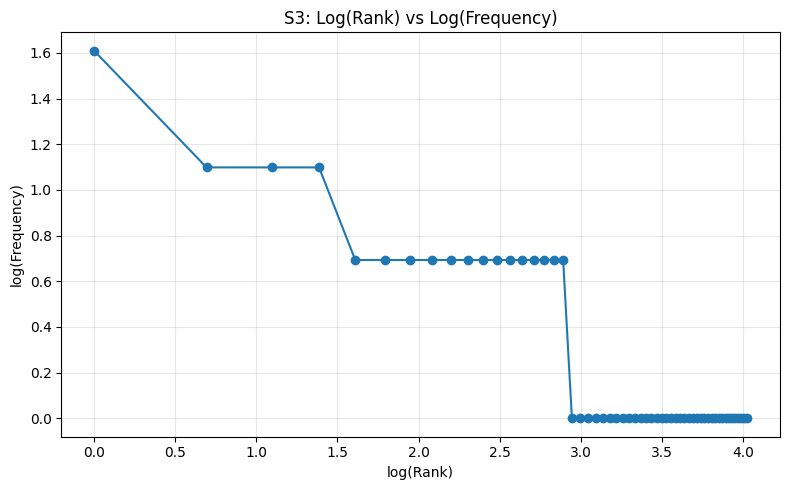

Top 5 bigrams in S1


,Bigram,Frequency
0,"(., the)",5
1,"(keeps, disconnecting)",4
2,"(yesterday, .)",4
3,"(., i)",4
4,"(disconnecting, since)",2


Top 5 bigrams in S3


,Bigram,Frequency
0,"(keeps, disconnecting)",3
1,"(disconnecting, since)",2
2,"(since, yesterday.)",2
3,"(n't, know)",2
4,"(know, changed)",2


In [14]:
S1 = [
    token.lower()
    for _, text in tickets
    for token in my_tokenize(text)
]

S2 = [
    token for token in S1
    if not is_punctuation(token)
]

S3 = [
    token
    for result in processed
    for token in result["Final token list"]
]

S4 = [porter.stem(token) for token in S3]


def corpus_statistics(name, tokens):
    total = len(tokens)
    unique = len(set(tokens))

    return {
        "Set": name,
        "Total tokens": total,
        "Unique tokens": unique,
        "TTR": unique / total if total else 0
    }


stats_table = pd.DataFrame([
    corpus_statistics("S1", S1),
    corpus_statistics("S2", S2),
    corpus_statistics("S3", S3),
    corpus_statistics("S4", S4)
])

display(stats_table)

print("Top 10 tokens in S1")
display(pd.DataFrame(
    Counter(S1).most_common(10),
    columns=["Token", "Frequency"]
))

print("Top 10 tokens in S3")
display(pd.DataFrame(
    Counter(S3).most_common(10),
    columns=["Token", "Frequency"]
))


import math

frequency_counts = Counter(S3).most_common()

ranks = list(range(1, len(frequency_counts) + 1))
frequencies = [frequency for _, frequency in frequency_counts]

plt.figure(figsize=(8, 5))

plt.plot(
    [math.log(rank) for rank in ranks],
    [math.log(freq) for freq in frequencies],
    marker="o"
)

plt.xlabel("log(Rank)")
plt.ylabel("log(Frequency)")
plt.title("S3: Log(Rank) vs Log(Frequency)")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()



print("Top 5 bigrams in S1")

display(pd.DataFrame(
    Counter(bigrams(S1)).most_common(5),
    columns=["Bigram", "Frequency"]
))

print("Top 5 bigrams in S3")

display(pd.DataFrame(
    Counter(bigrams(S3)).most_common(5),
    columns=["Bigram", "Frequency"]
))

In [15]:
examples = ["university", "was", "crashes", "opening"]

for word in examples:
    porter_result = porter.stem(word)

    tagged = nltk.pos_tag([word])
    tag = tagged[0][1]

    wn_pos = get_wordnet_pos(tag)
    lemma = lemmatizer.lemmatize(word, wn_pos)

    print(
        f"Word: {word:12} "
        f"Porter: {porter_result:12} "
        f"Lemma: {lemma}"
    )

Word: university   Porter: univers      Lemma: university
Word: was          Porter: wa           Lemma: be
Word: crashes      Porter: crash        Lemma: crash
Word: opening      Porter: open         Lemma: opening


# Q1. Preprocessing Pipeline

Some final tokens, such as `n't`, `s`, and `ca`, are not complete words. They can occur when contractions such as `isn't`, `don't`, and `can't` are split into smaller parts by the tokenizer. These fragments may remain in the final tokens if they are not removed by the stopword list. They are tokenization artifacts rather than meaningful standalone words.

# Q2. Regular Expressions

Some capitalized words are capitalized only because they appear at the beginning of a sentence, such as `The`, `Password`, and `Server`. These are sentence-initial words rather than proper nouns. Other words, such as `Python`, `Wi-Fi`, and `Dr`, may be capitalized because they are technical names, abbreviations, or titles. The exact number can be determined by checking the extracted capitalized words against their positions in the original sentences.

# Q3. Custom Tokenizer

The number of tickets tokenized differently is given by the comparison table's `Different?` column. The count should include only tickets T01–T14. The custom tokenizer is designed to preserve contractions, hyphenated words, decimals, version numbers, email addresses, URLs, and phone numbers as single tokens. The standard `word_tokenize()` function may split some of these into multiple tokens because it follows different tokenization rules.

# Q4. Stemming and Lemmatization

Over-stemming occurs when a stemmer removes too much of a word, potentially merging unrelated words or producing an unnatural root. For example, the Porter stemmer reduces `university` to `univers`, which is not a complete dictionary word.

Under-stemming occurs when related words are not reduced to the same stem, even though they share a common root. Different stemming algorithms use different suffix-removal rules, so related words may remain different. Specific examples should be selected from the generated stemming comparison table.

WordNet lemmatization uses vocabulary and grammatical information to identify dictionary forms, whereas stemming relies mainly on suffix-removal rules. Therefore, lemmatization can produce more meaningful results when grammatical context is considered.

# Q5. Corpus Statistics

Type-Token Ratio (TTR) is calculated as the number of unique tokens divided by the total number of tokens. S1 contains all tokens, including punctuation. S2 removes punctuation, S3 removes stopwords, and S4 applies Porter stemming to S3.

These operations change both the total number of tokens and the number of unique tokens. Stemming combines certain word forms into common stems, generally reducing lexical diversity. Consequently, TTR changes across S1, S2, S3, and S4. The exact direction and magnitude of the change depend on the dataset and the preprocessing results.

# Q6. Interpretation

(a) Difference between word_tokenize() and my_tokenize():

The word `isn't` may be split into `is` and `n't` by `word_tokenize()`, whereas the custom tokenizer is designed to preserve it as a single token. This difference occurs because the custom regular expression explicitly recognizes contractions.

(b) An undesirable stemming result:

The Porter stemmer reduces `university` to `univers`, which is not a complete English dictionary word. This illustrates that stemming removes suffixes according to rules rather than understanding the meaning of a word.

(c) An example where POS-aware lemmatization is better:

The word `was` can be lemmatized to `be` when identified as a verb. POS-aware lemmatization uses grammatical information to determine the correct base form, whereas stemming relies on suffix-removal rules and may not produce the correct dictionary form.

(d) Conclusion:

Stemming is useful for reducing related word forms and simplifying text analysis, but it can produce unnatural roots. POS-aware lemmatization generally produces more linguistically meaningful base forms because it considers grammatical information and vocabulary.